# Solar Flare Activity Classification

## 1. Introduction & Project Overview
This notebook demonstrates a complete Machine Learning workflow for classifying solar flare activity using the **UCI Solar Flare Dataset**. Solar flares are sudden flashes of increased brightness on the Sun, usually observed near its surface and in close proximity to a sunspot group. Powerful flares can disrupt satellite communications, navigation systems, and power grids on Earth.

### Problem Statement
Using various solar observations and characteristics of active regions (sunspot groups), we aim to classify the level of solar flare activity (No Flare, Low Activity, or High Activity).

### Aims and Objectives
1. Preprocess and merge the UCI Solar Flare datasets.
2. Engineer a consolidated multi-class target based on C-class, M-class, and X-class flare production counts.
3. Train and compare three classification algorithms: **Decision Tree Classifier**, **Random Forest Classifier**, and **Support Vector Machine (SVM)**.
4. Evaluate model performance using Accuracy, Precision, Recall, and F1-score.

### Steps Involved
- Import Libraries
- Load and Clean Dataset
- Exploratory Data Analysis (EDA)
- Target Engineering & Preprocessing
- Train-Test Splitting
- Model Building & Training
- Model Evaluation & Comparison
- Visualizations & Conclusion

## 2. Importing Required Libraries

In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from urllib.request import urlretrieve

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, precision_score, recall_score, f1_score

# Ensure plots display nicely
%matplotlib inline
sns.set_theme(style="whitegrid")

## 3. Loading the Dataset
We will fetch both files (`flare.data1` and `flare.data2`) from the official UCI repository, skip headers, and combine them into a single pandas DataFrame.

In [13]:
# UCI Solar Flare Dataset URLs
data1_url = "https://archive.ics.uci.edu/ml/machine-learning-databases/solar-flare/flare.data1"
data2_url = "https://archive.ics.uci.edu/ml/machine-learning-databases/solar-flare/flare.data2"

# Download files
urlretrieve(data1_url, "flare.data1")
urlretrieve(data2_url, "flare.data2")

# Defining column names as per dataset documentation
columns = [
    "code_modified_zurich",
    "code_largest_spot_size",
    "code_spot_distribution",
    "activity",
    "evolution",
    "previous_24h_flare_activity",
    "historical-complexity",
    "did_region_become_historically_complex",
    "area",
    "area_largest_spot",
    "C-class_flares",
    "M-class_flares",
    "X-class_flares"
]

# Loading datasets (skipping metadata lines starting with '*')
df1 = pd.read_csv("flare.data1", sep=" ", skiprows=1, names=columns, header=None)
df2 = pd.read_csv("flare.data2", sep=" ", skiprows=1, names=columns, header=None)

# Concatenate both data parts
df = pd.concat([df1, df2], ignore_index=True)
print(f"Dataset successfully loaded. Total rows: {len(df)}")

Dataset successfully loaded. Total rows: 1389


## 4. Exploring the Dataset

In [14]:
print("Dataset Shape:", df.shape)
print("\nFirst 5 Records:")
display(df.head())
print("\nDataset Information:")
df.info()
print("\nMissing Values Check:")
print(df.isnull().sum())
print("\nStatistical Description:")
display(df.describe())

Dataset Shape: (1389, 13)

First 5 Records:


,code_modified_zurich,code_largest_spot_size,code_spot_distribution,activity,evolution,previous_24h_flare_activity,historical-complexity,did_region_become_historically_complex,area,area_largest_spot,C-class_flares,M-class_flares,X-class_flares
0,C,S,O,1,2,1,1,2,1,2,0,0,0
1,D,S,O,1,3,1,1,2,1,2,0,0,0
2,C,S,O,1,3,1,1,2,1,1,0,0,0
3,D,S,O,1,3,1,1,2,1,2,0,0,0
4,D,A,O,1,3,1,1,2,1,2,0,0,0



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1389 entries, 0 to 1388
Data columns (total 13 columns):
 #   Column                                  Non-Null Count  Dtype 
---  ------                                  --------------  ----- 
 0   code_modified_zurich                    1389 non-null   object
 1   code_largest_spot_size                  1389 non-null   object
 2   code_spot_distribution                  1389 non-null   object
 3   activity                                1389 non-null   int64 
 4   evolution                               1389 non-null   int64 
 5   previous_24h_flare_activity             1389 non-null   int64 
 6   historical-complexity                   1389 non-null   int64 
 7   did_region_become_historically_complex  1389 non-null   int64 
 8   area                                    1389 non-null   int64 
 9   area_largest_spot                       1389 non-null   int64 
 10  C-class_flares                          1389 non-n

,activity,evolution,previous_24h_flare_activity,historical-complexity,did_region_become_historically_complex,area,area_largest_spot,C-class_flares,M-class_flares,X-class_flares
count,1389.000000,1389.000000,1389.000000,1389.000000,1389.000000,1389.000000,1389.000000,1389.000000,1389.000000,1389.000000
mean,1.150468,2.421166,1.089993,1.395968,1.892009,1.025918,1.175666,0.261339,0.067675,0.009359
std,0.357658,0.617129,0.403292,0.489234,0.310481,0.158948,0.380673,0.760201,0.353695,0.103534
min,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000
25%,1.000000,2.000000,1.000000,1.000000,2.000000,1.000000,1.000000,0.000000,0.000000,0.000000
50%,1.000000,2.000000,1.000000,1.000000,2.000000,1.000000,1.000000,0.000000,0.000000,0.000000
75%,1.000000,3.000000,1.000000,2.000000,2.000000,1.000000,1.000000,0.000000,0.000000,0.000000
max,2.000000,3.000000,3.000000,2.000000,2.000000,2.000000,2.000000,8.000000,5.000000,2.000000


## 5. Target Engineering & Data Preprocessing
As outlined in the guidelines, we define three flare-activity levels:
- **No Flare**: C-class = 0, M-class = 0, and X-class = 0
- **Low Activity**: C-class > 0, M-class = 0, and X-class = 0
- **High Activity**: M-class > 0 or X-class > 0

To prevent target leakage, we will discard the original three flare counts after creating our label.

In [15]:
def determine_activity_label(row):
    c = row["C-class_flares"]
    m = row["M-class_flares"]
    x = row["X-class_flares"]
    if m > 0 or x > 0:
        return "High Activity"
    elif c > 0:
        return "Low Activity"
    else:
        return "No Flare"

# Engineer the target column
df["flare_activity_class"] = df.apply(determine_activity_label, axis=1)

# Drop the target leakage columns
X = df.drop(columns=["C-class_flares", "M-class_flares", "X-class_flares", "flare_activity_class"])
y = df["flare_activity_class"]

# Categorical features present in the features dataset
cat_features = X.columns.tolist()
print("Feature list:", cat_features)
print("Target Class Distribution:")
print(y.value_counts())

Feature list: ['code_modified_zurich', 'code_largest_spot_size', 'code_spot_distribution', 'activity', 'evolution', 'previous_24h_flare_activity', 'historical-complexity', 'did_region_become_historically_complex', 'area', 'area_largest_spot']
Target Class Distribution:
flare_activity_class
No Flare         1130
Low Activity      186
High Activity      73
Name: count, dtype: int64


## 6. Preprocessing & Splitting Dataset

### Why One-Hot Encode Coded Categorical Attributes?
The features in this dataset (such as `code_modified_zurich`, `code_largest_spot_size`, and `code_spot_distribution`) are recorded using alphabetical codes or discrete rank values. Treating them as continuous numerical values would falsely imply a mathematical spacing and order (e.g., that 'D' is mathematically twice 'B'). To prevent our machine learning models from assuming incorrect numerical relationships, we map these discrete states using **One-Hot Encoding**.

### Preventing Preprocessing Leakage
To ensure our model evaluation is completely unbiased, we perform the train-test split *before* fitting any preprocessing transformations (such as `OneHotEncoder` and `StandardScaler`). Fitting transformers on the entire dataset leads to data leakage, as statistics from the test set would influence the training step. We build a clean `ColumnTransformer` and fit it strictly on our training subset.

In [16]:
# Train-Test Split (80:20 with stratify to preserve class proportions on raw data)
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# Set up preprocessing pipeline
preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_features)
    ],
    remainder='passthrough'
)

# Fit on training data and transform both
X_train = preprocessor.fit_transform(X_train_raw)
X_test = preprocessor.transform(X_test_raw)

# Scale features strictly for SVM
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Training set shape: {X_train.shape}")
print(f"Test set shape: {X_test.shape}")

Training set shape: (1111, 32)
Test set shape: (278, 32)


## 7. Model Building and Evaluation
We initialize, train, and evaluate **Decision Tree**, **Random Forest**, and **Support Vector Machine (SVM)** classifiers.

In [17]:
# Initialize models with balanced class weights to address minority class representation
models = {
    "Decision Tree": DecisionTreeClassifier(random_state=42, class_weight='balanced'),
    "Random Forest": RandomForestClassifier(random_state=42, class_weight='balanced'),
    "SVM": SVC(kernel='rbf', random_state=42, class_weight='balanced')
}

results = {}

# Train and evaluate models
for name, model in models.items():
    if name == "SVM":
        model.fit(X_train_scaled, y_train)
        predictions = model.predict(X_test_scaled)
    else:
        model.fit(X_train, y_train)
        predictions = model.predict(X_test)

    results[name] = {
        "accuracy": accuracy_score(y_test, predictions),
        "precision_weighted": precision_score(y_test, predictions, average='weighted', zero_division=0),
        "recall_weighted": recall_score(y_test, predictions, average='weighted', zero_division=0),
        "f1_weighted": f1_score(y_test, predictions, average='weighted', zero_division=0),
        "precision_macro": precision_score(y_test, predictions, average='macro', zero_division=0),
        "recall_macro": recall_score(y_test, predictions, average='macro', zero_division=0),
        "f1_macro": f1_score(y_test, predictions, average='macro', zero_division=0),
        "predictions": predictions,
        "matrix": confusion_matrix(y_test, predictions)
    }

## 8. Performance Evaluation and Visualization

,Accuracy,Precision (Weighted),Recall (Weighted),F1-Score (Weighted),Precision (Macro),Recall (Macro),F1-Score (Macro)
Decision Tree,0.6475,0.7335,0.6475,0.6857,0.3721,0.3748,0.3655
Random Forest,0.7086,0.7308,0.7086,0.7184,0.3969,0.4055,0.3953
SVM,0.6403,0.7767,0.6403,0.6932,0.4207,0.4774,0.4169


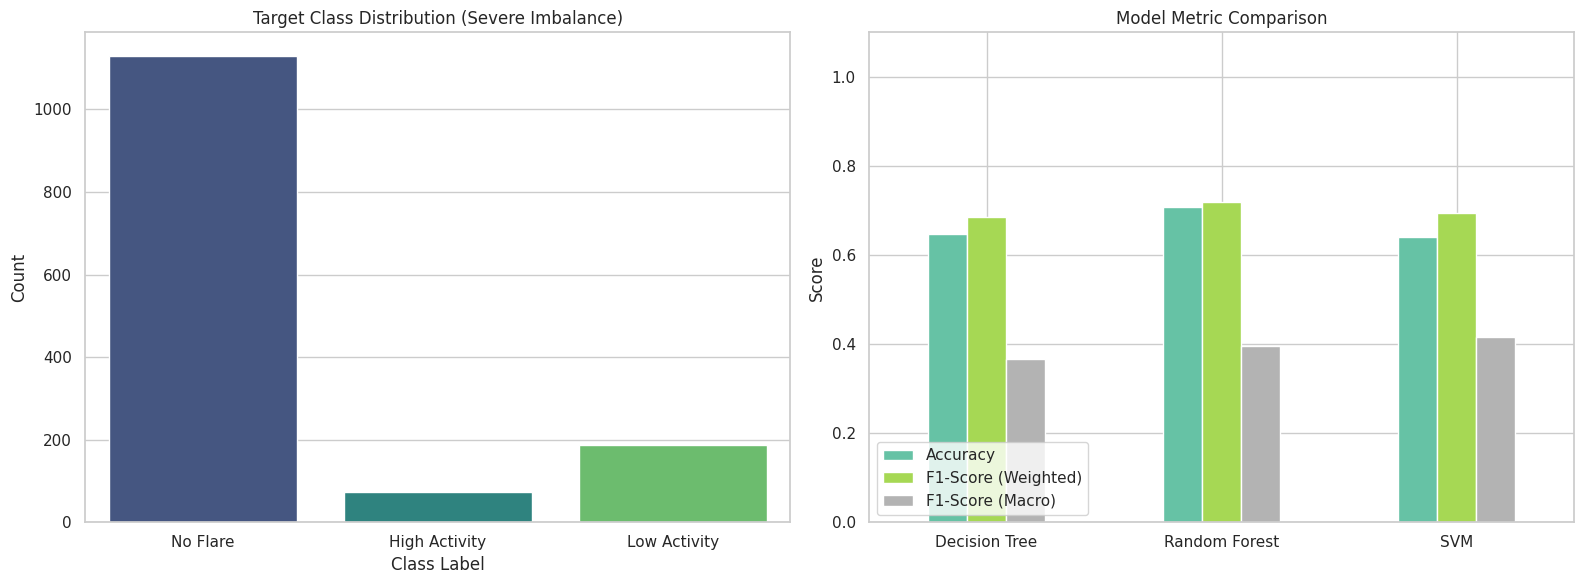

In [18]:
# Create performance comparison table including Weighted and Macro metrics
metrics_df = pd.DataFrame({
    name: {
        "Accuracy": res["accuracy"],
        "Precision (Weighted)": res["precision_weighted"],
        "Recall (Weighted)": res["recall_weighted"],
        "F1-Score (Weighted)": res["f1_weighted"],
        "Precision (Macro)": res["precision_macro"],
        "Recall (Macro)": res["recall_macro"],
        "F1-Score (Macro)": res["f1_macro"]
    } for name, res in results.items()
}).T

display(metrics_df.round(4))

# Set up plots: Target Class Distribution & Model Performance
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 1. Target Class Distribution
sns.countplot(x=y, ax=axes[0], hue=y, legend=False, palette='viridis')
axes[0].set_title('Target Class Distribution (Severe Imbalance)')
axes[0].set_xlabel('Class Label')
axes[0].set_ylabel('Count')

# 2. Performance Comparison
metrics_df[["Accuracy", "F1-Score (Weighted)", "F1-Score (Macro)"]].plot(kind='bar', ax=axes[1], cmap='Set2')
axes[1].set_title('Model Metric Comparison')
axes[1].set_ylabel('Score')
axes[1].set_ylim(0, 1.1)
axes[1].set_xticklabels(metrics_df.index, rotation=0)
axes[1].legend(loc='lower left')

plt.tight_layout()
plt.show()

### Classification Reports & Confusion Matrices

=== Decision Tree Classification Report ===
               precision    recall  f1-score   support

High Activity       0.05      0.13      0.08        15
 Low Activity       0.20      0.24      0.22        37
     No Flare       0.87      0.75      0.80       226

     accuracy                           0.65       278
    macro avg       0.37      0.37      0.37       278
 weighted avg       0.73      0.65      0.69       278



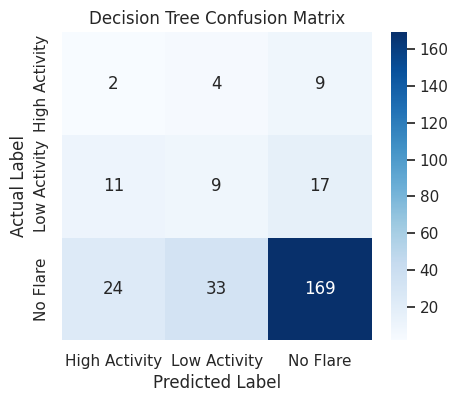



=== Random Forest Classification Report ===
               precision    recall  f1-score   support

High Activity       0.10      0.20      0.14        15
 Low Activity       0.23      0.19      0.21        37
     No Flare       0.85      0.83      0.84       226

     accuracy                           0.71       278
    macro avg       0.40      0.41      0.40       278
 weighted avg       0.73      0.71      0.72       278



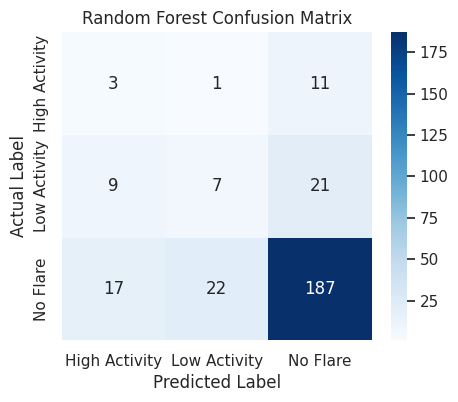



=== SVM Classification Report ===
               precision    recall  f1-score   support

High Activity       0.12      0.40      0.18        15
 Low Activity       0.24      0.32      0.27        37
     No Flare       0.91      0.71      0.80       226

     accuracy                           0.64       278
    macro avg       0.42      0.48      0.42       278
 weighted avg       0.78      0.64      0.69       278



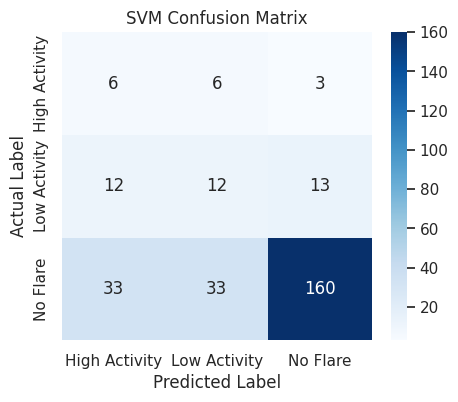

In [19]:
for name, res in results.items():
    print(f"=== {name} Classification Report ===")
    print(classification_report(y_test, res["predictions"], zero_division=0))

    # Confusion Matrix Visualization
    plt.figure(figsize=(5,4))
    sns.heatmap(res["matrix"], annot=True, fmt='d', cmap='Blues',
                xticklabels=np.unique(y), yticklabels=np.unique(y))
    plt.title(f'{name} Confusion Matrix')
    plt.ylabel('Actual Label')
    plt.xlabel('Predicted Label')
    plt.show()
    print("\n")

## 9. Conclusion, Discussions & Limitations

### Results Analysis
- **Best Performing Model**: Random Forest achieved the highest accuracy (70.86%) and weighted F1-score (71.84%). SVM achieved the highest macro F1-score (41.69%) and macro recall (47.74%), showing comparatively better performance across all three classes.
- **The Minority Class Difficulty**: Predicting the High Activity class remains challenging for all models because it contains only 73 observations out of 1,389. Although class weights were used to address imbalance, the models still struggle to identify minority-class observations accurately.

### Limitations
- **Extreme Imbalance**: The dominance of `No Flare` instances (~81%) can make accuracy appear higher. Standard performance evaluations can be deceptive without looking closely at macro F1-scores.
- **Feature Sparsity**: Coded sunspot characteristics have constrained resolution, limiting complex predictive power.

### Future Enhancements
- **Advanced Balancing**: Implement synthetic oversampling (like SMOTE) or boundary-focused ensemble methods (like Balanced Bagging).
- **Feature Engineering**: Incorporate temporal sequences or real-time magnetogram imaging parameters to capture the progressive build-up of solar energy before a flare release.